# Case 1: The junior's join: why did the score jump?
*Applies: Feature engineering from the customer table: ratios, recency, counts, cohort age,
basket signals · Encoding categoricals; scaling numerics; which models care*

A Portuguese bank rang 41,188 clients between May 2008 and November 2010 to sell a term
deposit, and the week's model ranks whom to ring. On Monday and Tuesday it read the customer
table alone and scored a validation AUC of 0.76. Overnight a junior on the team joins two more
feeds to that table: the economic indicators the bank's research desk keeps, and the call log.
The score jumps. Before anyone celebrates, you measure what each join added and read the jump
through recall and the call bill, because accuracy will barely move.

**Who needs the answer.** The campaign head, who decides whom the call centre rings next
month, and Kavya Nair, Kalpa's senior analyst, who signs off the same method for Kalpa's nudge.

**The questions on the way.** What does the week's pipeline give us before the join? What
does each join add? Why does accuracy hide the jump? What does the jump promise in rupees?
Where do the encoder and the scaler learn their numbers?

**You will be able to** score three feature sets on one split, read a jump through AUC,
recall and the bill, and show that the pipeline's encoder and scaler learn from training rows only.

**Search terms:** feature engineering for machine learning, sklearn ColumnTransformer,
one-hot encoding, StandardScaler pipeline.

## What does the week's pipeline give us before the join?
The cell below is the week's shared code. It downloads the bank's file once into a cache in
your home folder, seals 20 percent of the rows as the test set (the envelope on the wall),
and splits the rest 75 to 25 into training and validation rows with seed 42. The customer
table is the 13 columns known about a client on the morning of a call. The scorer at the end
is today's addition: it reports AUC, accuracy, recall, Tuesday's call bill at the threshold
40 / 1,240 = 0.032, and how many buyers sit in the top 1,000 scores.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, GREY = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#A9A3D2"

def check(label, ok):
    """Print one line that starts PASS or FAIL, and keep the notebook running either way."""
    print(("PASS  " if ok else "FAIL  ") + label)

# The Week 5 pipeline every case notebook starts from: the same file, columns, split and baseline.
import io, zipfile, pathlib, urllib.request
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # verified 28 October 2026
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

# The customer table on the morning of the call: who the client is and how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
# Joined on Wednesday from other feeds: the call log and the economic indicators.
CALL_LOG = ["duration"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

CALL_RS, MISSED_RS = 40, 1200            # Tuesday's costs: one call, one missed buyer's margin
THRESHOLD = CALL_RS / (CALL_RS + MISSED_RS)

def score(columns, tr=None, va=None):
    """Fit on training rows, score validation rows, and return the numbers the day quotes."""
    tr = train if tr is None else tr
    va = val if va is None else va
    ytr, yva = (tr["y"] == "yes").astype(int), (va["y"] == "yes").astype(int)
    model = logistic(columns, tr).fit(tr[columns], ytr)
    p = model.predict_proba(va[columns])[:, 1]
    tn, fp, fn, tp = confusion_matrix(yva, (p >= 0.5).astype(int)).ravel()
    tn2, fp2, fn2, tp2 = confusion_matrix(yva, (p >= THRESHOLD).astype(int)).ravel()
    top = yva.values[np.argsort(-p)[:1000]].sum()
    return {"columns": len(columns), "AUC": round(roc_auc_score(yva, p), 4),
            "accuracy": round(accuracy_score(yva, (p >= 0.5).astype(int)), 4),
            "TP": tp, "FP": fp, "FN": fn, "recall": round(tp / (tp + fn), 3),
            "bill_Rs": int(fp2 * CALL_RS + fn2 * MISSED_RS), "buyers_in_top_1000": int(top)}, model, p

bank = load_bank()
train, val, test = week_split(bank)
y_train = (train["y"] == "yes").astype(int)
y_val = (val["y"] == "yes").astype(int)
print(f"{len(bank):,} calls: train {len(train):,}, validation {len(val):,}, "
      f"test {len(test):,} (sealed until Friday)")
print(f"Base rate: {y_train.mean():.2%} of training calls ended in a deposit")

41,188 calls: train 24,712, validation 8,238, test 8,238 (sealed until Friday)
Base rate: 11.27% of training calls ended in a deposit


In [2]:
check("41,188 calls loaded from the public file", len(bank) == 41188)
check("train, validation and test are 24,712, 8,238 and 8,238 rows",
      (len(train), len(val), len(test)) == (24712, 8238, 8238))
check("the base rate sits between 11 and 12 percent", 0.11 < y_train.mean() < 0.12)

PASS  41,188 calls loaded from the public file
PASS  train, validation and test are 24,712, 8,238 and 8,238 rows
PASS  the base rate sits between 11 and 12 percent


## What does each join add?
Three feature sets go in, one after another: the customer table (13 columns), the customer
table plus the five economic columns, and both plus the one call-log column, `duration`.

**Predict before you run.** The customer table scores 0.76. What do the two joins add?
(A) about 0.01 each; (B) the economy about 0.03 and the call log about 0.14; (C) the economy
about 0.14 and the call log about 0.03; (D) nothing, since the model already knows the client.

In [3]:
SETS = {"customer table": PROFILE + HISTORY,
        "+ economy": PROFILE + HISTORY + ECONOMY,
        "+ economy + call log": PROFILE + HISTORY + ECONOMY + CALL_LOG}
results = {}
for name, cols in SETS.items():
    results[name], _, _ = score(cols)
table = pd.DataFrame(results).T[["columns", "AUC", "accuracy", "recall", "bill_Rs", "buyers_in_top_1000"]]
table

,columns,AUC,accuracy,recall,bill_Rs,buyers_in_top_1000
customer table,13.0,0.7613,0.8971,0.188,279000.0,404.0
+ economy,18.0,0.7946,0.8986,0.227,280040.0,460.0
+ economy + call log,19.0,0.9324,0.9074,0.420,118800.0,572.0


**What happened.** B. AUC climbs from 0.761 to 0.795 with the economy and to 0.932 with the
call log, a jump of 0.14 from one column. Accuracy at 0.5 moves from 0.897 to 0.907, one
point, because 88.7 percent of calls end in no and calling nobody already scores 0.887. A
jump this size from a single column is the first thing a senior doubts; case 2 asks whether
that column could ever exist when the call list is made.

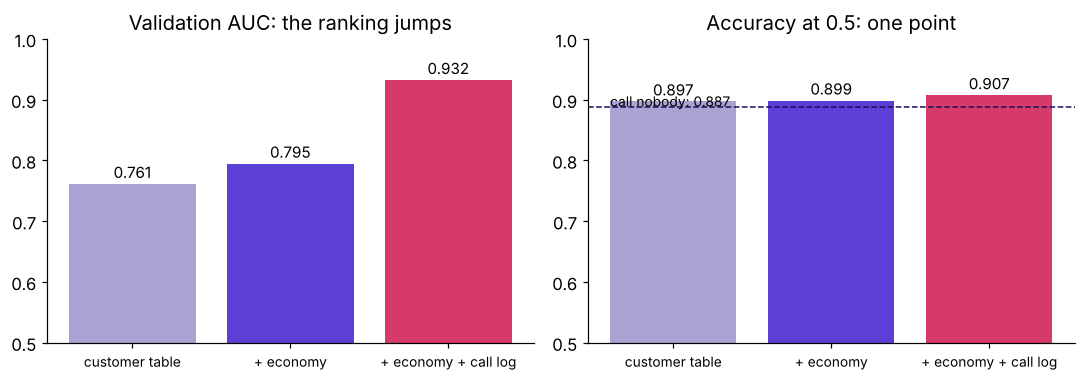

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
names = list(table.index)
colours = [GREY, VIOLET, ROSE]
axes[0].bar(names, table["AUC"].astype(float), color=colours)
axes[0].set_ylim(0.5, 1.0); axes[0].set_title("Validation AUC: the ranking jumps")
axes[1].bar(names, table["accuracy"].astype(float), color=colours)
axes[1].axhline(0.8874, color=INK, ls="--", lw=1); axes[1].text(-0.4, 0.889, "call nobody: 0.887", fontsize=9)
axes[1].set_ylim(0.5, 1.0); axes[1].set_title("Accuracy at 0.5: one point")
for ax, col in zip(axes, ["AUC", "accuracy"]):
    for i, v in enumerate(table[col].astype(float)):
        ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=10)
    ax.tick_params(axis="x", labelsize=9)
plt.tight_layout(); plt.show()

## Why does accuracy hide the jump, and what does the jump promise in rupees?
Accuracy counts right answers at one cut, and nine in ten answers are an easy no. The
decision lives elsewhere: whom to ring. Read the jump through three numbers the campaign head
uses: recall at 0.5 (of the buyers, how many the list finds), the call bill at Tuesday's
threshold (every call Rs 40, every missed buyer Rs 1,200 of lost margin), and the buyers
found if the centre can ring only 1,000 people.

**Predict before you run.** On these 8,238 validation calls, the third feature set's bill is
(A) about the same as the customer table's; (B) about Rs 1.6 lakh lower; (C) higher, because
it calls more people.

In [5]:
bill = table[["recall", "bill_Rs", "buyers_in_top_1000"]].copy()
bill["bill_lakh"] = (bill["bill_Rs"].astype(float) / 1e5).round(2)
saved = int(bill.loc["+ economy", "bill_Rs"] - bill.loc["+ economy + call log", "bill_Rs"])
print(f"The call-log join promises Rs {saved/1e5:.2f} lakh less on 8,238 calls, "
      f"and {int(bill.loc['+ economy + call log', 'buyers_in_top_1000']) - int(bill.loc['+ economy', 'buyers_in_top_1000'])} "
      f"more buyers in the top 1,000.")
bill

The call-log join promises Rs 1.61 lakh less on 8,238 calls, and 112 more buyers in the top 1,000.


,recall,bill_Rs,buyers_in_top_1000,bill_lakh
customer table,0.188,279000.0,404.0,2.79
+ economy,0.227,280040.0,460.0,2.80
+ economy + call log,0.420,118800.0,572.0,1.19


**What happened.** B. Recall at 0.5 nearly doubles, from 0.23 to 0.42, and the bill falls
from about Rs 2.80 lakh to about Rs 1.19 lakh, a promise of Rs 1.61 lakh saved on 8,238
calls. That promise is what a junior would take to the campaign head. Whether the bank can
collect it depends on one fact about one column, which case 2 checks.

## Where do the encoder and the scaler learn their numbers?
This is the implementation engineer's question. The pipeline's scaler learns each numeric
column's mean and spread, and the one-hot encoder learns each column's list of categories,
when `fit` is called on training rows. Validation and test rows are transformed with those
training numbers. A hurried analyst scales the whole file first and splits afterwards, so
the sealed test rows quietly shape every feature: a small leak through the split, and the
habit that later lets bigger ones through.

**Predict before you run.** How many rows did the fitted scaler see? (A) 41,188; (B) 32,950;
(C) 24,712.

In [6]:
_, model, _ = score(SETS["+ economy"])
scaler = model.named_steps["prep"].named_transformers_["num"]
encoder = model.named_steps["prep"].named_transformers_["cat"]
num_cols = model.named_steps["prep"].transformers_[0][2]
print("rows the scaler saw:", int(scaler.n_samples_seen_))
print("job categories the encoder learned:", len(encoder.categories_[0]), list(encoder.categories_[0])[:5], "...")
hurried = StandardScaler().fit(bank[num_cols])          # the trap: all rows, test included
compare = pd.DataFrame({"mean from training rows": scaler.mean_.round(3),
                        "mean from all rows": hurried.mean_.round(3)}, index=num_cols)
compare.head(5)

rows the scaler saw: 24712
job categories the encoder learned: 12 ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management'] ...


,mean from training rows,mean from all rows
age,40.005,40.024
campaign,2.571,2.568
previous,0.175,0.173
emp.var.rate,0.085,0.082
cons.price.idx,93.578,93.576


**What happened.** C. The scaler saw the 24,712 training rows and nothing else, and the
encoder learned 12 job categories, `unknown` among them, from the same rows. The means from
all rows differ only in the second or third decimal on this file, which is why the habit
looks harmless; on a file where the future differs from the past, the same habit carries the
future into training. The rule: every encoder and scaler sits inside the pipeline and is fitted
on training rows only.

In [7]:
check("adding the economy lifts AUC", results["+ economy"]["AUC"] > results["customer table"]["AUC"])
check("the call-log join lifts AUC by more than 0.10",
      results["+ economy + call log"]["AUC"] - results["+ economy"]["AUC"] > 0.10)
check("accuracy moves by less than 0.02 across all three sets",
      table["accuracy"].astype(float).max() - table["accuracy"].astype(float).min() < 0.02)
check("the scaler was fitted on training rows only", int(scaler.n_samples_seen_) == len(train))

PASS  adding the economy lifts AUC
PASS  the call-log join lifts AUC by more than 0.10
PASS  accuracy moves by less than 0.02 across all three sets
PASS  the scaler was fitted on training rows only


## What does case 1 hand to case 2?
| Feature set | Columns | Validation AUC | Recall at 0.5 | Bill at 0.032 |
|---|---|---|---|---|
| Customer table | 13 | 0.761 | 0.19 | about Rs 2.79 lakh |
| + economy | 18 | 0.795 | 0.23 | about Rs 2.80 lakh |
| + economy + call log | 19 | 0.932 | 0.42 | about Rs 1.19 lakh |

Every join lifted the score and the last one lifted it most. Case 2 asks the prediction-time
question of every column: on the morning the call list is made, is this value known?